In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd

2024-08-30 15:53:58.959502: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-08-30 15:54:00.596550: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [3]:
#importamos los datos desde un archivo .csv
datos = pd.read_csv("datos.csv")

In [5]:
# obtenemos informacion metadatos del tipo de datos que tenemos
datos.info()
data = pd.DataFrame(datos)
data.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   celcius    7 non-null      int64  
 1   farenheit  7 non-null      float64
dtypes: float64(1), int64(1)
memory usage: 240.0 bytes


(7, 2)

In [4]:
#obtenemos una vista previa de los datos
datos.head()

,celcius,farenheit
0,-40,-40.0
1,-10,14.0
2,0,32.0
3,8,46.4
4,15,59.0


<Axes: xlabel='celcius', ylabel='farenheit'>

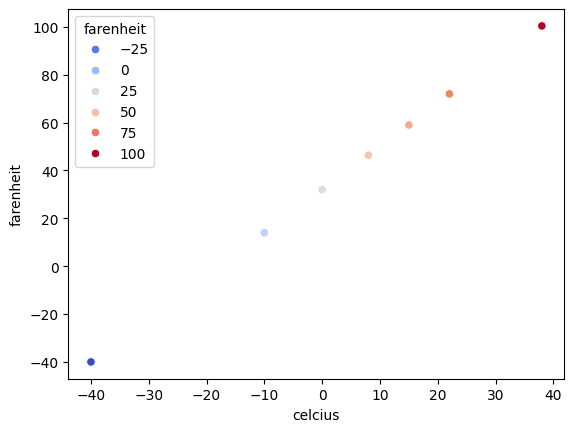

In [9]:
# Visualizamos los datos con seaborn
import seaborn as sb
sb.scatterplot(x='celcius',y='farenheit',data=datos, 
               hue='farenheit',     # Muestra el 
               palette='coolwarm')

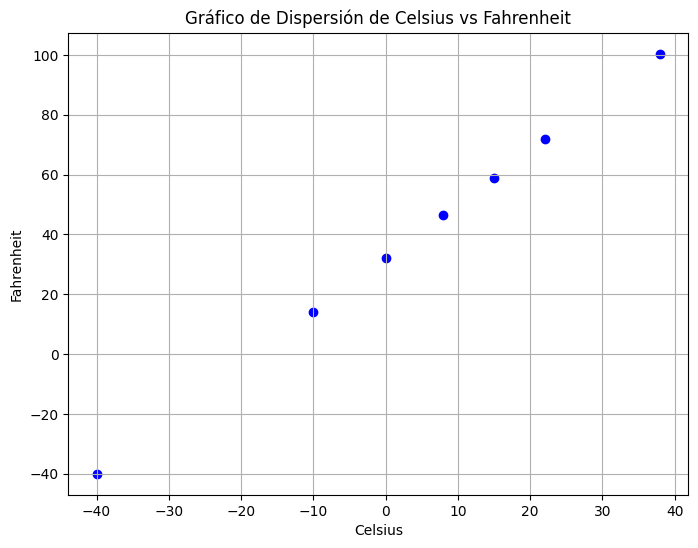

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
df = data
plt.figure(figsize=(8, 6))
plt.scatter(df['celcius'], df['farenheit'], color='blue', marker='o')
plt.title('Gráfico de Dispersión de Celsius vs Fahrenheit')
plt.xlabel('Celsius')
plt.ylabel('Fahrenheit')
plt.grid(True)
plt.show()

In [12]:
#Durbin-Watson
# La prueba de Durbin-Watson se utiliza para detectar la autocorrelación en los residuos de un modelo de regresión. La autocorrelación ocurre cuando los errores en una observación están correlacionados con los errores en otra observación. Esto puede ser un problema especialmente en series temporales.

import pandas as pd
import statsmodels.api as sm
# Definir las variables independientes y dependientes
X = df['celcius']
y = df['farenheit']

# Agregar una constante a las variables independientes
X = sm.add_constant(X)

# Ajustar el modelo de regresión lineal
model = sm.OLS(y, X).fit()
# Obtener el valor de Durbin-Watson
dw = sm.stats.durbin_watson(model.resid)

# Imprimir el valor
print(f'Valor de Durbin-Watson: {dw}')


Valor de Durbin-Watson: 2.716535130120447


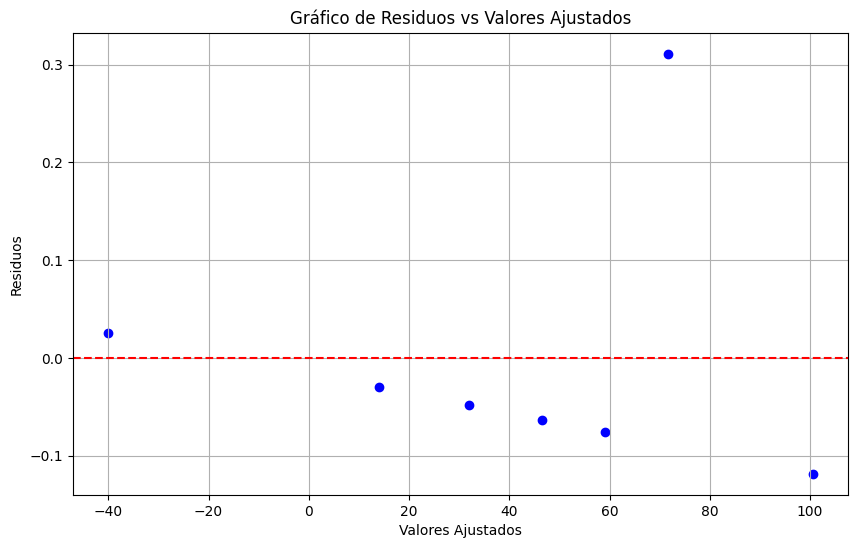

In [13]:
#verificar la homoscedasticidad 
# Obtener los residuos del modelo
residuals = model.resid

# Obtener los valores ajustados (predicciones)
fitted_values = model.fittedvalues

import matplotlib.pyplot as plt

# Crear el gráfico de residuos
plt.figure(figsize=(10, 6))
plt.scatter(fitted_values, residuals, color='blue', marker='o')
plt.axhline(0, color='red', linestyle='--')  # Línea horizontal en 0
plt.title('Gráfico de Residuos vs Valores Ajustados')
plt.xlabel('Valores Ajustados')
plt.ylabel('Residuos')
plt.grid(True)
plt.show()

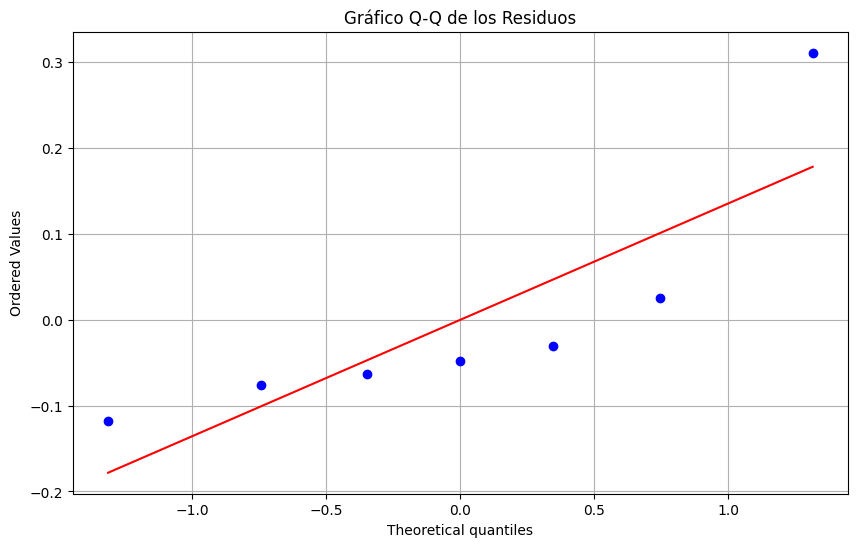

In [14]:
import scipy.stats as stats

# Crear el gráfico Q-Q
plt.figure(figsize=(10, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Gráfico Q-Q de los Residuos')
plt.grid(True)
plt.show()

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calcular el VIF para cada variable independiente
vif_data = pd.DataFrame()
vif_data["variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif_data)

  variable      VIF
0    const  1.04136
1  celcius  1.00000


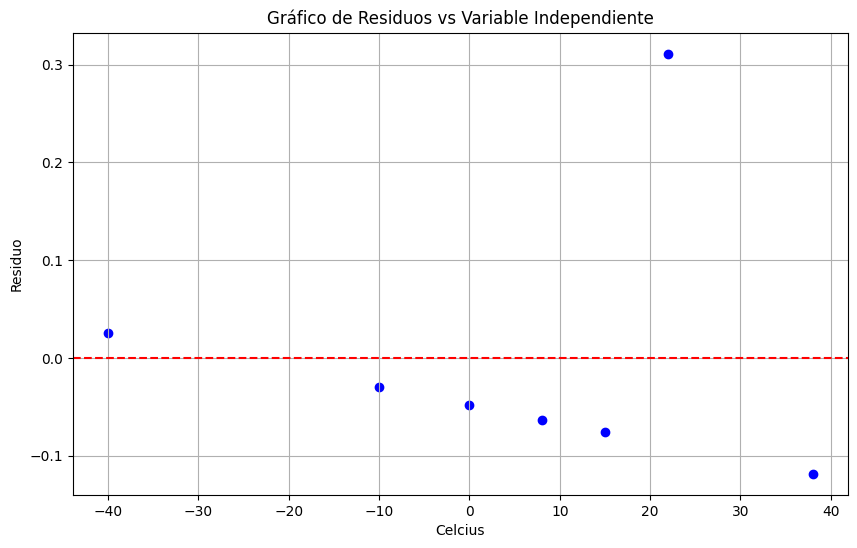

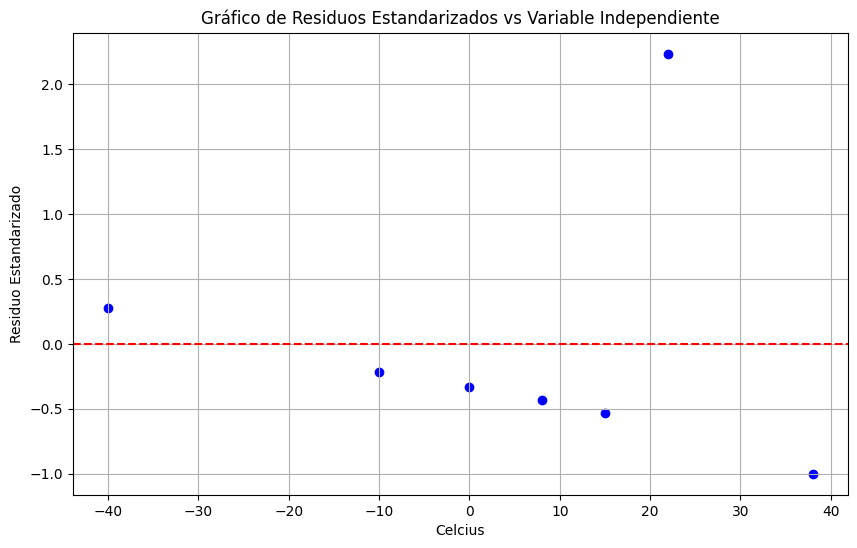

TypeError: stem() got an unexpected keyword argument 'use_line_collection'

<Figure size 1000x600 with 0 Axes>

In [17]:
# Definir las variables independientes y dependientes
X = df[['celcius']]
y = df['farenheit']

# Agregar una constante a las variables independientes
X = sm.add_constant(X)

# Ajustar el modelo de regresión lineal
model = sm.OLS(y, X).fit()

# Obtener residuos e influencia
influence = model.get_influence()
standardized_residuals = influence.resid_studentized_internal
cooks_d = influence.cooks_distance[0]

# Gráfico de Residuos
plt.figure(figsize=(10, 6))
plt.scatter(X['celcius'], model.resid, color='blue', marker='o')
plt.axhline(0, color='red', linestyle='--')
plt.title('Gráfico de Residuos vs Variable Independiente')
plt.xlabel('Celcius')
plt.ylabel('Residuo')
plt.grid(True)
plt.show()

# Gráfico de Residuos Estandarizados
plt.figure(figsize=(10, 6))
plt.scatter(X['celcius'], standardized_residuals, color='blue', marker='o')
plt.axhline(0, color='red', linestyle='--')
plt.title('Gráfico de Residuos Estandarizados vs Variable Independiente')
plt.xlabel('Celcius')
plt.ylabel('Residuo Estandarizado')
plt.grid(True)
plt.show()

# Gráfico de Distancia de Cook
plt.figure(figsize=(10, 6))
plt.stem(cooks_d, markerfmt="o", basefmt=" ", use_line_collection=True)
plt.title('Distancia de Cook para Cada Observación')
plt.xlabel('Índice de Observación')
plt.ylabel('Distancia de Cook')
plt.grid(True)
plt.show()

In [11]:
# Preparamos los datos separandolo en :
# 1.- Caracteristicas  (x) 
# 2.- Etiqueta o respuesta (y)
# En este ejemplo las caracteristicas solo hay 1 los grados Celcius, a diferencia de los precios
# de casas que tienen muchas caracteristicas para determinar un precio i.e: #de cuartos, M2, zona, etc.

x_celsius = datos['celcius']
y_farenheit = datos['farenheit']
x_celsius.values # rray([-40, -10,   0,   8,  15,  22,  38])

#NOTA : Aqui hay que darle formato a los datos y para eso los procesamos

array([-40, -10,   0,   8,  15,  22,  38])

In [11]:
#Transformamos los valores de las caracteristicas es decir lo procesamos
x_celsius_procesada = x_celsius.values.reshape(-1,1)
y_farenheit_procesada = y_farenheit.values.reshape(-1,1)


In [13]:
#Creemos nuestro modelo de Regresion Linear
from sklearn.linear_model import LinearRegression
modelo = LinearRegression()

In [15]:
# Entremos el modelo
modelo.fit(x_celsius_procesada,y_farenheit_procesada)
print("Modelo entrenado.. listo para predecir")

Modelo entrenado.. listo para predecir


In [19]:
# Visualizamos el score del modelo para saber que tan bien entreno. 
# Entre mas se acerce al 1 indica que esta muy bien entrenada.
modelo.score(x_celsius_procesada,y_farenheit_procesada)

0.9999898106465813

In [17]:
# Para hacer predicciones :
modelo.predict([[123]])

array([[253.67457653]])